# Binary-source separation FI: mean photon interarrival time and optical dimension

**10% Rayleigh fraction**

All Fisher information values are **per two-photon pair**. The physical model uses a frozen-flow von Kármán atmosphere $r_0=0.157921\,\mathrm m, L_0=22\,\mathrm m$, pixel pitch $a=0.0640625\,\mathrm m$, and wind speed $v=10\,\mathrm{m/s}$. Here $t/t_{\rm corr}=\bar u/L_0$ with $t_{\rm corr}=L_0/v$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from binary_fi import (
    binary_time_data, binary_dimension_data,
    rayleigh_separation, PITCH_M, L0_M, WIND_M_S,
)

plt.rcParams.update({
    'font.size': 14, 'axes.labelsize': 15, 'axes.titlesize': 16,
    'xtick.labelsize': 15, 'ytick.labelsize': 15, 'legend.fontsize': 12,
    'axes.linewidth': 1, 'xtick.major.width': 1.8,
    'ytick.major.width': 1.8, 'xtick.minor.width': 1.2,
    'ytick.minor.width': 1.2, 'grid.linewidth': 1.0,
})

## Simulation settings

`PAPER_MODE=True` computes the full D=128 time scan and D=8,16,32,64,128 dimension scan. This runs all five original numerical models and may be computationally expensive, especially the D=128 PPT solver. Set `PAPER_MODE=False` for a substantially smaller test; its curves are not publication-resolution results.

In [5]:
PAPER_MODE = True    # False = faster sanity check
RAYLEIGH_FRACTION = 0.10
MEAN_U_OVER_L0_FOR_D_SCAN = 1e-3
SAVE_FIGURES = True

TIME_DELTA_OVERRIDE = 0.005

if PAPER_MODE:
    D_TIME = 128
    D_VALUES = (8, 16, 32, 64, 128)
    TIME_LAG_ANCHORS = np.geomspace(1e-5, 1e2, 10)  # FI anchors
    TIME_MEANS = np.geomspace(1e-5, 1e2, 11)   # 11 plotted points
    D_LAG_ANCHORS = np.geomspace(1e-5, 1.0, 10)  # dimension anchors
else:
    D_TIME = 8
    D_VALUES = (8, 12)
    TIME_LAG_ANCHORS = np.geomspace(1e-5, 1e2, 6)
    TIME_MEANS = np.geomspace(1e-5, 1e2, 5)
    D_LAG_ANCHORS = np.geomspace(1e-5, 1.0, 5)

print(f'10% Rayleigh: Delta(D={D_TIME}) = {rayleigh_separation(D_TIME, RAYLEIGH_FRACTION):.8g} rad/pixel')
print('Dimensions in right panel:', D_VALUES)
print('Mean t/t_corr for dimension scan:', MEAN_U_OVER_L0_FOR_D_SCAN)
time_delta_actual = (TIME_DELTA_OVERRIDE if PAPER_MODE and TIME_DELTA_OVERRIDE is not None
                     else rayleigh_separation(D_TIME, RAYLEIGH_FRACTION))
print('Time scan Delta:', time_delta_actual, '; equivalent Rayleigh fraction:',
      time_delta_actual * D_TIME / (2*np.pi))
print('Time plot: %d mean points evaluated from %d fixed-lag anchors'
      % (len(TIME_MEANS), len(TIME_LAG_ANCHORS)))


10% Rayleigh: Delta(D=128) = 0.0049087385 rad/pixel
Dimensions in right panel: (8, 16, 32, 64, 128)
Mean t/t_corr for dimension scan: 0.001
Time scan Delta: 0.005 ; equivalent Rayleigh fraction: 0.10185916357881303
Time plot: 11 mean points evaluated from 10 fixed-lag anchors


## Generate the numerical data

In [8]:
# Left panel: FI versus t/t_corr for D=128 in paper mode.
zu = binary_time_data(
    d=D_TIME,
    rayleigh_fraction=RAYLEIGH_FRACTION,
    delta_override=TIME_DELTA_OVERRIDE if PAPER_MODE else None,
    lag_anchor_x=TIME_LAG_ANCHORS,
    mean_x=TIME_MEANS,
    include_ppt=True,
    kalman_nx=250,
    verbose=True,
)

[Time 1/10] D=128, u/L0=1e-05
[Time 2/10] D=128, u/L0=5.995e-05
[Time 3/10] D=128, u/L0=0.0003594
[Time 4/10] D=128, u/L0=0.002154
[Time 5/10] D=128, u/L0=0.01292
[Time 6/10] D=128, u/L0=0.07743
[Time 7/10] D=128, u/L0=0.4642
[Time 8/10] D=128, u/L0=2.783
[Time 9/10] D=128, u/L0=16.68
[Time 10/10] D=128, u/L0=100
[Time Kalman 1/11] mean u/L0=1e-05
[Time Kalman 2/11] mean u/L0=5.012e-05
[Time Kalman 3/11] mean u/L0=0.0002512
[Time Kalman 4/11] mean u/L0=0.001259
[Time Kalman 5/11] mean u/L0=0.00631
[Time Kalman 6/11] mean u/L0=0.03162
[Time Kalman 7/11] mean u/L0=0.1585
[Time Kalman 8/11] mean u/L0=0.7943
[Time Kalman 9/11] mean u/L0=3.981
[Time Kalman 10/11] mean u/L0=19.95
[Time Kalman 11/11] mean u/L0=100


In [9]:
# Right panel: FI versus D, always at 10% Rayleigh.
zd = binary_dimension_data(
    d_values=D_VALUES,
    rayleigh_fraction=RAYLEIGH_FRACTION,
    mean_u_over_L0=MEAN_U_OVER_L0_FOR_D_SCAN,
    lag_anchor_x=D_LAG_ANCHORS,
    include_ppt=True,
    kalman_nx=250,
    verbose=True,
)

[Dimension D=8, 1/10] u/L0=1e-05
[Dimension D=8, 2/10] u/L0=3.594e-05
[Dimension D=8, 3/10] u/L0=0.0001292
[Dimension D=8, 4/10] u/L0=0.0004642
[Dimension D=8, 5/10] u/L0=0.001668
[Dimension D=8, 6/10] u/L0=0.005995
[Dimension D=8, 7/10] u/L0=0.02154
[Dimension D=8, 8/10] u/L0=0.07743
[Dimension D=8, 9/10] u/L0=0.2783
[Dimension D=8, 10/10] u/L0=1
[Dimension D=16, 1/10] u/L0=1e-05
[Dimension D=16, 2/10] u/L0=3.594e-05
[Dimension D=16, 3/10] u/L0=0.0001292
[Dimension D=16, 4/10] u/L0=0.0004642
[Dimension D=16, 5/10] u/L0=0.001668
[Dimension D=16, 6/10] u/L0=0.005995
[Dimension D=16, 7/10] u/L0=0.02154
[Dimension D=16, 8/10] u/L0=0.07743
[Dimension D=16, 9/10] u/L0=0.2783
[Dimension D=16, 10/10] u/L0=1
[Dimension D=32, 1/10] u/L0=1e-05
[Dimension D=32, 2/10] u/L0=3.594e-05
[Dimension D=32, 3/10] u/L0=0.0001292
[Dimension D=32, 4/10] u/L0=0.0004642
[Dimension D=32, 5/10] u/L0=0.001668
[Dimension D=32, 6/10] u/L0=0.005995
[Dimension D=32, 7/10] u/L0=0.02154
[Dimension D=32, 8/10] u/L0=0.07

## Paper figure: Poisson FI versus mean time and optical dimension

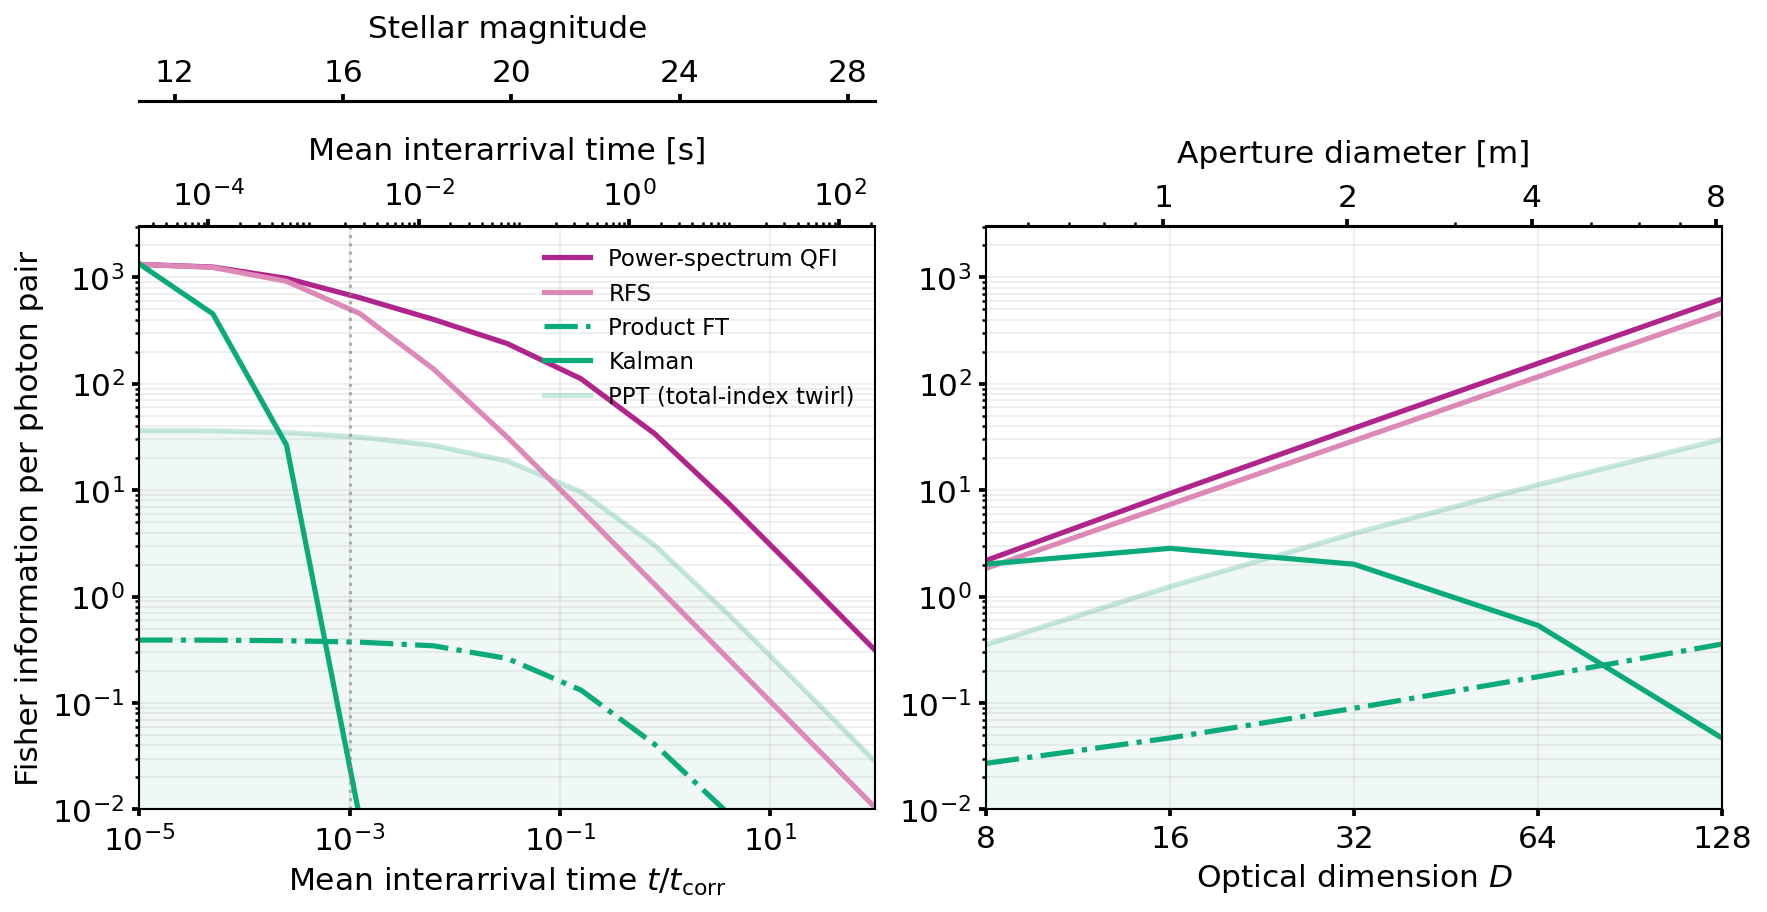

In [11]:
regime = 'rayleigh'
L0 = L0_M
v = WIND_M_S
a = PITCH_M
figsize = (12, 6.5)
ylim = (1e-2, 3e3)

xu = np.asarray(zu['mean_u_over_L0'])
mask = zd['regime'] == regime
xd = zd['D'][mask]

# naming convention (Poisson arrivals):
# Power-spectrum QFI -> atm. aware RFS
# RFS_FI_pair -> atm. blind RFS
# Product_FT_FI_pair -> universal classical receiver: direct imaging with correlations
# Kalman_mean_cadence_FI_pair -> Kalman filtering

curves = [
    ('Poisson_power_QFI_pair', 'power_QFI_pair', 'Power-spectrum QFI', '#AF258C', '-'),
    ('Poisson_RFS_FI_pair', 'RFS_FI_pair', 'RFS', '#DD89B7', '-'),
    ('Poisson_Product_FT_FI_pair', 'Product_FT_FI_pair', 'Product FT', '#0BAA7A', '-.'),
    ('Kalman_mean_cadence_FI_pair', 'Kalman_mean_cadence_FI_pair',
     'Kalman', '#0BAA7A', '-'),
]

fig, axs = plt.subplots(1, 2, figsize=figsize, dpi=150)
for ku, kd, label, color, ls in curves:
    axs[0].loglog(xu, zu[ku], lw=2.5, ls=ls, color=color, label=label)
    axs[1].loglog(xd, zd[kd][mask], lw=2.5, ls=ls, color=color)

fill_color, fill_alpha, y_min_bound = '#95D3C0', 0.15, 1e-2
ppt_time = zu['Poisson_PPT_upper_total_index_mixed_pair']
ppt_dim = zd['PPT_upper_total_index_mixed_pair'][mask]
axs[0].loglog(xu, ppt_time, lw=2.5, color=fill_color,
              label='PPT (total-index twirl)', zorder=1, alpha=0.5)
axs[0].fill_between(xu, ppt_time, y2=y_min_bound,
                    color=fill_color, alpha=fill_alpha, zorder=1)
axs[1].loglog(xd, ppt_dim, lw=2.5, color=fill_color, zorder=1, alpha=0.5)
axs[1].fill_between(xd, ppt_dim, y2=y_min_bound,
                    color=fill_color, alpha=fill_alpha, zorder=1)

axs[0].set_xlabel(r'Mean interarrival time $t/t_{\rm corr}$')
axs[1].set_xlabel(r'Optical dimension $D$')
axs[0].set_ylabel('Fisher information per photon pair')
axs[0].set_xlim(1e-5, 1e2)
axs[1].set_xlim(8, 128)
axs[0].axvline(1e-3, color='gray', ls=':', alpha=0.6)
axs[1].set_xscale('log', base=2)
axs[1].set_xticks([8, 16, 32, 64, 128])
axs[1].set_xticklabels(['8', '16', '32', '64', '128'])
for ax in axs:
    ax.set_ylim(*ylim)
    ax.grid(True, which='both', alpha=0.2)
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)

ax_time = axs[0].secondary_xaxis(
    'top', functions=(lambda x: x*L0/v, lambda t: t*v/L0))
ax_time.set_xlabel('Mean interarrival time [s]', labelpad=10)
ax_time.spines['top'].set_linewidth(1.0)
ax_time.set_xticks([1e-4, 1e-2, 1, 1e2])

ax_aperture = axs[1].secondary_xaxis(
    'top', functions=(lambda D: D*a, lambda A: A/a))
ax_aperture.set_xlabel('Aperture diameter [m]', labelpad=10)
ax_aperture.set_xticks([0.5, 1, 2, 4, 8])
ax_aperture.set_xticklabels(['0.5', '1', '2', '4', '8'])
ax_aperture.spines['top'].set_linewidth(1.0)

# Paper's AB/3631-Jy photon-rate convention.
bandwidth_nm, lambda_nm, throughput, diameter_m = 1.0, 550.0, 0.25, 8.2
h, Fnu0 = 6.62607015e-34, 3631e-26
lambda_m, bandwidth_m = lambda_nm*1e-9, bandwidth_nm*1e-9
R0 = np.pi*(diameter_m/2)**2*throughput*Fnu0*bandwidth_m/(h*lambda_m)
def x_to_mag(x):
    return 2.5*np.log10(R0*np.maximum(np.asarray(x),1e-300)*L0/v)
def mag_to_x(m):
    return 10**(np.asarray(m)/2.5)*v/(R0*L0)
ax_mag = axs[0].secondary_xaxis('top', functions=(x_to_mag, mag_to_x))
ax_mag.spines['top'].set_position(('outward', 60))
ax_mag.spines['top'].set_linewidth(1.5)
ax_mag.set_xlabel('Stellar magnitude', labelpad=10)
ax_mag.set_xticks([12, 16, 20, 24, 28])
ax_mag.set_xticklabels(['12', '16', '20', '24', '28'])
ax_mag.minorticks_off()

axs[0].legend(frameon=False, loc='best', fontsize=11)
fig.tight_layout()
fig.subplots_adjust(top=0.72, wspace=0.15)

if SAVE_FIGURES:
    suffix = 'paper' if PAPER_MODE else 'quick_check'
    fig.savefig(f'RFS_binary_10pct_Rayleigh_{suffix}.pdf', bbox_inches='tight')
    fig.savefig(f'RFS_binary_10pct_Rayleigh_{suffix}.png', dpi=300, bbox_inches='tight')
plt.show()